In [ ]:
# 1. Check GPU allocation
!nvidia-smi

# 2. Mount Google Drive to persist data and access the repository
from google.colab import drive
drive.mount('/content/drive')

/bin/bash: line 1: nvidia-smi: command not found
Mounted at /content/drive


In [8]:
# 1. Di chuyển vào thư mục chứa custom Ultralytics đã upload
# Hãy thay thế đường dẫn bên dưới bằng vị trí thực tế của bạn
%cd /content/drive/MyDrive/ppe_cv/Pruned-QAT-for-YOLOv8-on-waste-detection-tasks-for-edge-devices
# 2. Gỡ bản gốc để tránh xung đột
!pip uninstall -y ultralytics

# 3. Cài đặt bản custom (lệnh này sẽ cài đặt thư viện vào hệ thống Colab)
!pip install -e .

/content/drive/MyDrive/ppe_cv/Pruned-QAT-for-YOLOv8-on-waste-detection-tasks-for-edge-devices
Obtaining file:///content/drive/MyDrive/ppe_cv/Pruned-QAT-for-YOLOv8-on-waste-detection-tasks-for-edge-devices
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for ultralytics (pyproject.toml) ... done
  Created wheel for ultralytics: filename=ultralytics-8.3.231-0.editable-py3-none-any.whl size=11709 sha256=c7967d59454fd25e67273e9922fff3a037252404caf4b4c073a25e2996772f98
  Stored in directory: /tmp/pip-ephem-wheel-cache-7fjp6emr/wheels/6d/54/88/b24c9a513438bdb6003f090cbfc70bfc9b5fc534848fa36efd
Successfully built ultralytics


In [9]:
# Di chuyển về thư mục gốc của dự án
%cd /content/drive/MyDrive/ppe_cv/ppe_v2

# Kiểm tra lại xem đã đứng đúng thư mục chưa (sẽ thấy thư mục scripts, file data.yaml...)
!ls

/content/drive/MyDrive/ppe_cv/ppe_v2
bench.ipynb  demo.py			requirements.txt  yolov5_au.ipynb
config.py    experiments_dagshub.ipynb	runs		  yolov8_baseline.ipynb
data.yaml    README.md			scripts		  yolov8_prune.ipynb


In [ ]:
!pip install mlflow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.7/49.7 kB 2.4 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.5/50.5 kB 4.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 4.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.2/11.2 MB 107.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.6/3.6 MB 121.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 93.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 264.7/264.7 kB 25.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 148.8/148.8 kB 15.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 114.9/114.9 kB 11.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 212.0/212.0 kB 21.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 121.3/121.3 kB 11.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 132.2/132.2 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [ ]:
import os
os.environ["MLFLOW_ALLOW_FILE_STORE"] = "true"

In [ ]:
# Run sparsity training
# Note: Ensure configs/data.yaml has the correct dataset paths relative to your Drive
!python scripts/train.py \
    --mode sparsity \
    --weights /content/drive/MyDrive/ppe_cv/best_baseline.pt \
    --data data.yaml \
    --batch 16 \
    --epochs 80 \
    --device 0

New https://pypi.org/project/ultralytics/8.4.113 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/ppe_cv/ppe_v2/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=80, erasing=0.4, exist_ok=False, finetune=None, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/drive/MyDrive/ppe_cv/best_baseline.pt, momentum=0.937, mosai

In [ ]:
import mlflow
import os
import getpass

DAGSHUB_USER = input("Nhập DagsHub Username: ")
DAGSHUB_TOKEN = getpass.getpass("Nhập DagsHub Token: ")
DAGSHUB_REPO = input("Nhập tên DagsHub Repo (VD: ppe-project): ")

os.environ["MLFLOW_TRACKING_USERNAME"] = DAGSHUB_USER
os.environ["MLFLOW_TRACKING_PASSWORD"] = DAGSHUB_TOKEN
os.environ["MLFLOW_TRACKING_URI"] = f"https://dagshub.com/{DAGSHUB_USER}/{DAGSHUB_REPO}.mlflow"


Nhập DagsHub Username: TQanh23
Nhập DagsHub Token: ··········
Nhập tên DagsHub Repo (VD: ppe-project): ppe_v2


In [5]:
mlflow.set_experiment("YOLOv8_Sparsity_Pruning")

with mlflow.start_run(run_name="Phase1_Sparsity"):
    print("Đang tải dữ liệu lên MLflow...")

    mlflow.log_params({
        "mode": "sparsity",
        "epochs": 80,
        "batch_size": 16,
        "sr": 0.015
    })

    weights_dir = "/content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity3"

    mlflow.log_artifacts(weights_dir, artifact_path="sparsity_weights")

    print(f"Hoàn tất upload từ {weights_dir} lên MLflow!")

Đang tải dữ liệu lên MLflow...
Hoàn tất upload từ /content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity3 lên MLflow!
🏃 View run Phase1_Sparsity at: https://dagshub.com/TQanh23/ppe_v2.mlflow/#/experiments/8/runs/acc94ecb19ff48da8c3515ecb19ef666
🧪 View experiment at: https://dagshub.com/TQanh23/ppe_v2.mlflow/#/experiments/8


In [11]:
# 1. Tạo thư mục configs nếu chưa tồn tại
!mkdir -p /content/drive/MyDrive/ppe_cv/ppe_v2/configs

# 2. Tạo file pipeline.yaml mặc định
!echo "paths: {}" > /content/drive/MyDrive/ppe_cv/ppe_v2/configs/pipeline.yaml

In [12]:
# Run the visualization script
!python /content/drive/MyDrive/ppe_cv/ppe_v2/scripts/vis_bn_weight.py \
    --normal /content/drive/MyDrive/ppe_cv/best_baseline.pt \
    --sparse /content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity3/weights/last.pt \
    --output-dir assets/

/content/drive/MyDrive/ppe_cv/ppe_v2/scripts/vis_bn_weight.py:72: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()
Saved plots to /content/drive/MyDrive/ppe_cv/ppe_v2/assets


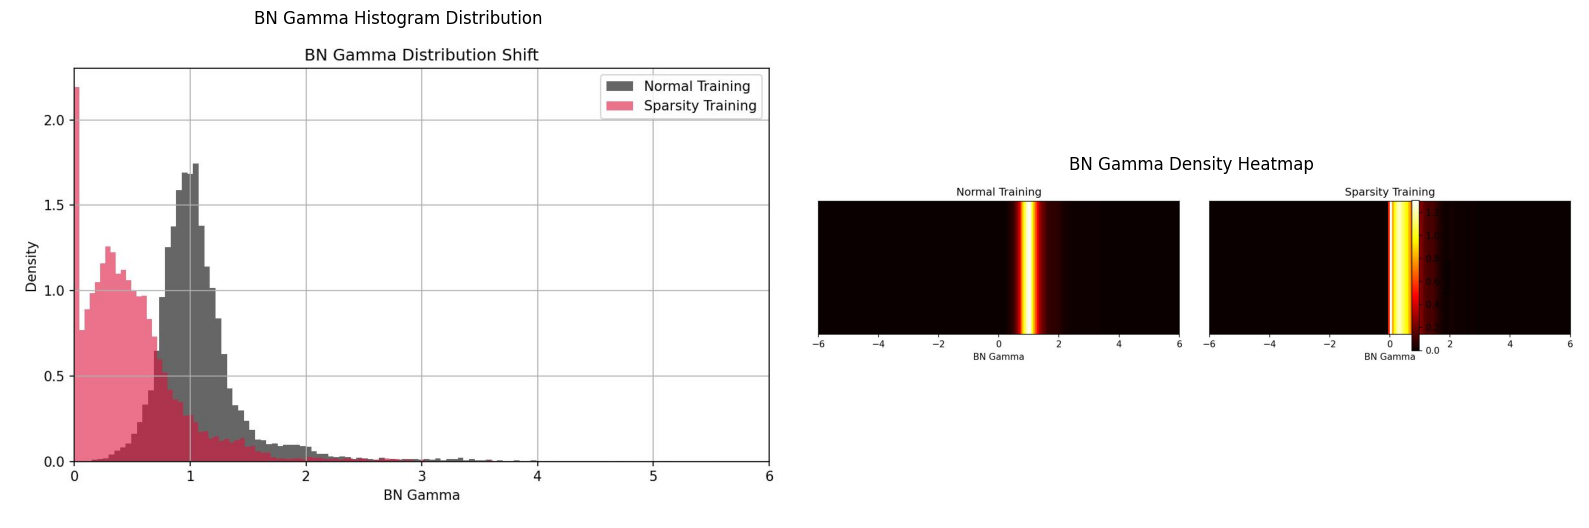

In [13]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os

# Render side-by-side plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

hist_path = 'assets/bn_gamma_hist.jpg'
heatmap_path = 'assets/bn_gamma_hist_heatmap.jpg'

if os.path.exists(hist_path) and os.path.exists(heatmap_path):
    axes[0].imshow(mpimg.imread(hist_path))
    axes[0].axis('off')
    axes[0].set_title("BN Gamma Histogram Distribution")

    axes[1].imshow(mpimg.imread(heatmap_path))
    axes[1].axis('off')
    axes[1].set_title("BN Gamma Density Heatmap")

    plt.tight_layout()
    plt.show()
else:
    print("Plot files not found. Check if Cell 6 executed successfully.")

In [18]:
# Evaluate model accuracy and measure inference latency
!python scripts/val.py \
    --weight /content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity3/weights/last.pt \
    --data data.yaml \
    --split val \
    --batch 16 \
    --imgsz 640 \
    --device cpu

Average Latency per image: 1167.00 ms
Approx FPS: 0.86
Ultralytics 8.3.231 🚀 Python-3.12.13 torch-2.11.0+cpu CPU (AMD EPYC 7B12)
Model summary (fused): 92 layers, 25,844,971 parameters, 0 gradients, 78.7 GFLOPs
val: Fast image access ✅ (ping: 0.9±0.4 ms, read: 0.2±0.1 MB/s, size: 71.7 KB)
val: Scanning /content/drive/MyDrive/ppe_cv/train_data/valid/labels.cache... 229 images, 19 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 229/229 2.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 22.1s/it 5:31
                   all        229       2019      0.731      0.683      0.705      0.363
                 boots         93        201      0.598      0.582       0.57      0.239
                gloves         78        157      0.675      0.423       0.48      0.173
                helmet        130        337      0.812      0.828       0.87      0.526
              no_boots         32         65       0.58      0.467    

In [15]:
import os

sparsity_weight_path = "/content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity3/weights/last.pt"

if os.path.exists(sparsity_weight_path):
    size_mb = os.path.getsize(sparsity_weight_path) / (1024 * 1024)
    print(f"✅ Phase 1 Complete! Output checkpoint ready for Phase 2:")
    print(f"   Path: {sparsity_weight_path} ({size_mb:.2f} MB)")
else:
    print(f"❌ Checkpoint file not found at {sparsity_weight_path}. Check your run directory.")

✅ Phase 1 Complete! Output checkpoint ready for Phase 2:
   Path: /content/drive/MyDrive/ppe_cv/ppe_v2/runs/train-sparsity3/weights/last.pt (49.63 MB)
